| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../7_METODOS_NUMERICOS_PARA_ODE/7_1_Euler.ipynb) | [⏩](../7_METODOS_NUMERICOS_PARA_ODE/7_3_Midpoint.ipynb) |

# 7.2 Método de Heun: predecir y corregir la pendiente

Heun mejora Euler promediando una pendiente al inicio y otra al final predicho. Es un Runge–Kutta explícito de orden dos. Derivaremos el predictor y el corrector, compararemos coste y precisión y estudiaremos un sistema epidémico donde conservación y positividad son distintas.

Los experimentos son autocontenidos y rápidos en CPU. Requisitos: derivadas, integrales, ecuaciones diferenciales ordinarias y errores numéricos. Ejecuta todas las celdas en orden. La solución exacta se usa como control cuando está disponible; en otros casos se compara contra una solución de referencia más precisa.

## 1. Problema de valor inicial y notación

Un problema de valor inicial tiene forma
$$y'(t)=f(t,y(t)),\qquad y(t_0)=y_0.$$
El estado $y$ puede ser un número o un vector. La función $f$ expresa la ley física y sus unidades son unidades de estado por unidades de tiempo. Bajo continuidad en $t$ y una condición local de Lipschitz en $y$, existe una solución única local; una implementación numérica no reemplaza estos supuestos.

Usaremos una malla $t_n=t_0+nh$ y una aproximación $y_n\approx y(t_n)$. Es esencial distinguir una evaluación de pendiente $f(t_n,y_n)$ de una actualización del estado. Para enfriamiento $y'=-ky$, el coeficiente $k>0$ tiene unidades de inverso del tiempo y la solución exacta es $y_0e^{-kt}$.

Un simulador introduce error de discretización además del error del modelo. Si una red se entrena con sus trayectorias, puede aprender ambas cosas. Por ello se estudian refinamiento, estabilidad y coste antes de usar los resultados como datos científicos.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import minimize_scalar
plt.rcParams.update({"figure.figsize":(9,4), "axes.grid":True, "font.size":11})
np.set_printoptions(precision=6,suppress=True)

## 2. Del trapecio al predictor explícito

La identidad exacta es
$$y(t+h)=y(t)+\int_t^{t+h} f(s,y(s))\,ds.$$
Aplicar trapecio sugeriría promediar $f(t,y)$ y $f(t+h,y(t+h))$, pero el valor final es desconocido. Heun lo aproxima con un predictor de Euler:
$$k_1=f(t_n,y_n),\quad \widetilde y=y_n+h k_1,$$
$$k_2=f(t_n+h,\widetilde y),\quad y_{n+1}=y_n+\frac h2(k_1+k_2).$$
No resolvemos ninguna ecuación implícita: el predictor es conocido antes de calcular $k_2$. Heun también se llama trapecio explícito; debe distinguirse del trapecio implícito que usa el estado final corregido dentro de $f$.

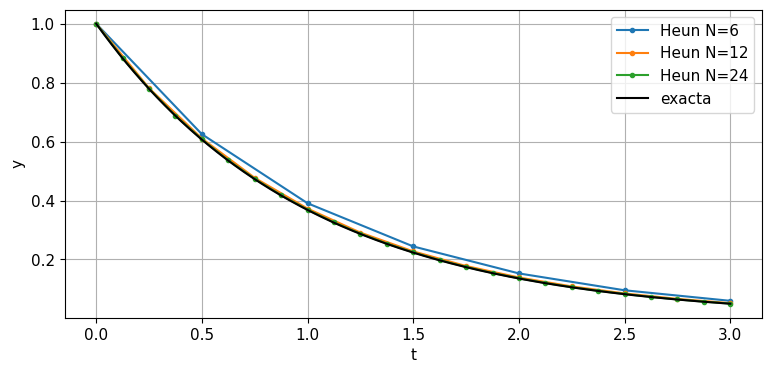

In [2]:
def heun(fun,tspan,y0,n):
    t=np.linspace(*tspan,n+1); h=t[1]-t[0]
    y=np.empty((n+1,np.atleast_1d(y0).size)); y[0]=np.atleast_1d(y0)
    for j in range(n):
        k1=np.asarray(fun(t[j],y[j]))
        predictor=y[j]+h*k1
        k2=np.asarray(fun(t[j+1],predictor))
        y[j+1]=y[j]+0.5*h*(k1+k2)
    return t,y

q=np.linspace(0,3,500)
for n in [6,12,24]:
    t,y=heun(lambda t,y:-y,(0,3),1.,n)
    plt.plot(t,y[:,0],"o-",markersize=3,label=f"Heun N={n}")
plt.plot(q,np.exp(-q),"k",label="exacta")
plt.xlabel("t"); plt.ylabel("y"); plt.legend(); plt.show()

**Interpretación.** El promedio corrige gran parte del sesgo de Euler. Para decaimiento lineal, $1-h+h^2/2$ supera $e^{-h}$ con pasos positivos, de modo que el sesgo cambia de dirección respecto a Euler.

## 3. Por qué tiene orden dos

Expandiendo $k_2$,
$$k_2=f+h f_t+h f_y f+O(h^2).$$
La actualización queda $y_{n+1}=y_n+h f+h^2(f_t+f_yf)/2+O(h^3)$, que coincide con Taylor de la solución hasta $h^2$, porque $y''=f_t+f_yf$. Por ello el defecto de un paso es $O(h^3)$ y el error global $O(h^2)$ en condiciones habituales.

En un sistema, $f_y$ es un jacobiano y el producto $f_yf$ un vector. No se necesita calcular ese jacobiano en el algoritmo: la segunda evaluación de $f$ reproduce la combinación de términos requerida.

Órdenes: [2.155563 2.072431 2.034981 2.017195]


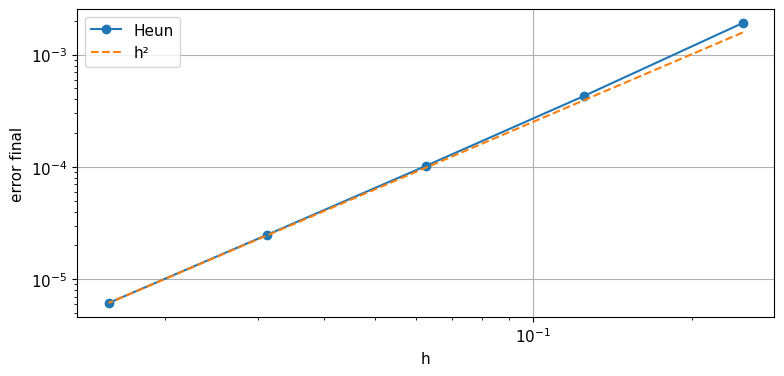

In [3]:
ns=np.array([12,24,48,96,192]); errors=[]
for n in ns:
    _,y=heun(lambda t,y:-y,(0,3),1.,n)
    errors.append(abs(y[-1,0]-np.exp(-3)))
errors=np.array(errors)
print("Órdenes:",np.log2(errors[:-1]/errors[1:]))
plt.loglog(3/ns,errors,"o-",label="Heun")
plt.loglog(3/ns,errors[-1]*(ns[-1]/ns)**2,"--",label="h²")
plt.xlabel("h"); plt.ylabel("error final"); plt.legend(); plt.show()

**Interpretación.** Al dividir el paso por dos se espera reducir el error aproximadamente por cuatro. Cada paso requiere dos evaluaciones de la ley física; una comparación con Euler debe incluir ese coste.

## 4. Geometría de las dos pendientes

Tomemos $y'=-y$, $y_0=1$, $h=0.6$. La primera pendiente es $-1$, el predictor vale $0.4$ y la segunda pendiente es $-0.4$. El promedio $-0.7$ produce $y_1=0.58$, mientras que Euler daría $0.4$ y el exacto $e^{-0.6}\approx0.54881$.

Las dos pendientes no son las pendientes exactas al comienzo y al final de la trayectoria: la segunda corresponde a un punto predicho. El nombre corrector se refiere a mejorar la actualización, no a obtener una solución exacta.

Euler: 0.4 Heun: 0.5800000000000001 Exacto: 0.5488116360940264


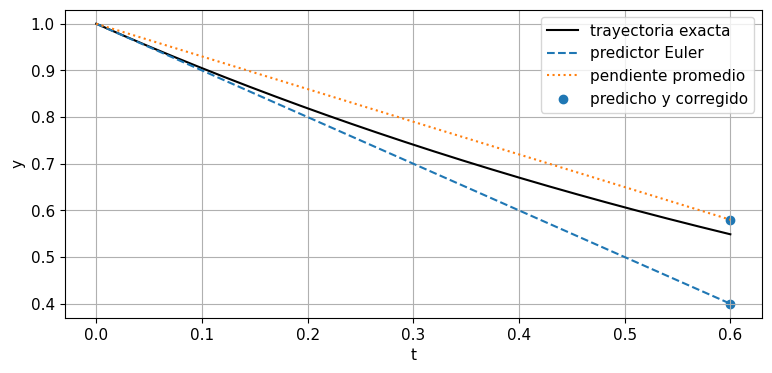

In [4]:
h=0.6; t=np.linspace(0,h,200)
initial=1.; k1=-initial; predicted=initial+h*k1; k2=-predicted
corrected=initial+h*(k1+k2)/2
plt.plot(t,np.exp(-t),"k",label="trayectoria exacta")
plt.plot(t,initial+k1*t,"--",label="predictor Euler")
plt.plot(t,initial+0.5*(k1+k2)*t,":",label="pendiente promedio")
plt.scatter([h,h],[predicted,corrected],label="predicho y corregido")
plt.xlabel("t"); plt.ylabel("y"); plt.legend(); plt.show()
print("Euler:",predicted,"Heun:",corrected,"Exacto:",np.exp(-h))

**Interpretación.** Heun mejora el resultado sin coincidir exactamente. La recta de pendiente promedio es una representación del paso, no una salida densa de orden garantizado dentro del intervalo.

## 5. Dependencia explícita del tiempo

Para $y'=t+y$, $y(0)=1$, la solución exacta es $y(t)=2e^t-t-1$. En la segunda evaluación se usa $t+h$; reutilizar $t$ rompe las condiciones de orden para problemas no autónomos.

En modelos con forzamientos, temporadas o controles, el tiempo es una entrada física. No debe omitirse porque algunos ejemplos sencillos no lo utilicen.

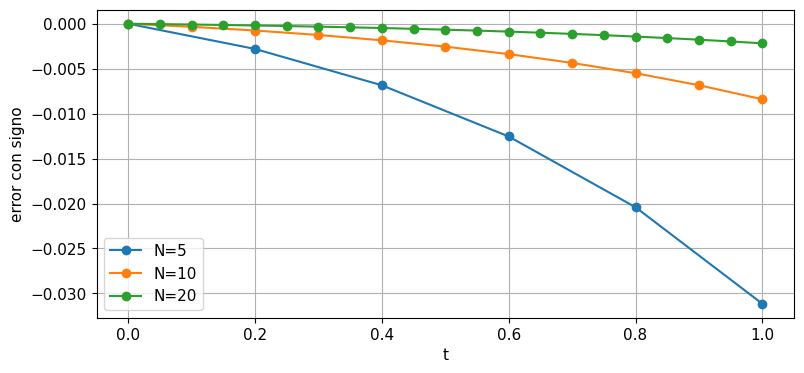

In [5]:
q=np.linspace(0,1,500); exact=lambda t:2*np.exp(t)-t-1
for n in [5,10,20]:
    t,y=heun(lambda t,y:t+y,(0,1),1.,n)
    plt.plot(t,y[:,0]-exact(t),"o-",label=f"N={n}")
plt.xlabel("t"); plt.ylabel("error con signo"); plt.legend(); plt.show()

**Interpretación.** La reducción del error confirma que se evalúan correctamente las dos abscisas temporales. Probar solo ecuaciones autónomas podría no detectar un error en esos tiempos.

## 6. Estabilidad para decaimiento lineal

Para $y'=\lambda y$, Heun tiene
$$R(z)=1+z+\frac{z^2}{2}.$$
En el eje real negativo, la estabilidad estricta exige $-2<z<0$, igual intervalo que Euler. El orden mayor mejora precisión dentro de la región, pero no amplía necesariamente el intervalo de estabilidad.

Para $z$ imaginario no nulo, $|R(i\omega h)|^2=1+(\omega h)^4/4>1$. Por ello en un oscilador sin amortiguación Heun tiene deriva energética creciente, aunque menor que Euler para pasos pequeños.

Deriva relativa: 0.010050040830009266


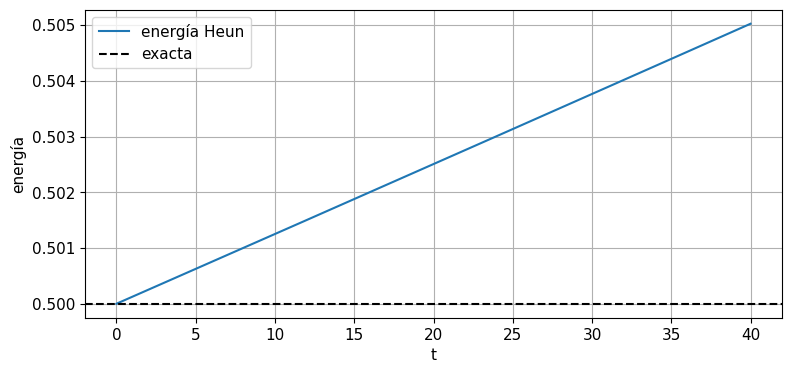

In [6]:
t,y=heun(lambda t,y:np.array([y[1],-y[0]]),(0,40),[1.,0.],400)
energy=0.5*np.sum(y*y,axis=1)
plt.plot(t,energy,label="energía Heun")
plt.axhline(0.5,color="k",linestyle="--",label="exacta")
plt.xlabel("t"); plt.ylabel("energía"); plt.legend(); plt.show()
print("Deriva relativa:",energy[-1]/energy[0]-1)

**Interpretación.** Aunque la deriva sea pequeña, no desaparece en integraciones prolongadas con paso fijo. Métodos geométricos pueden ser preferibles si conservar la estructura es el objetivo central.

## 7. Modelo SIR: conservación no equivale a positividad

En proporciones poblacionales,
$$S'=-\beta SI,\quad I'=\beta SI-\gamma I,\quad R'=\gamma I.$$
La suma de pendientes es cero y $S+I+R$ se conserva. Un método Runge–Kutta preserva esta invariante lineal salvo redondeo cuando cada evaluación usa un estado consistente. Sin embargo, pasos demasiado grandes pueden producir componentes negativas; conservar la suma no asegura estados físicos.

Error de conservación: 4.440892098500626e-16
Valor mínimo: 0.0


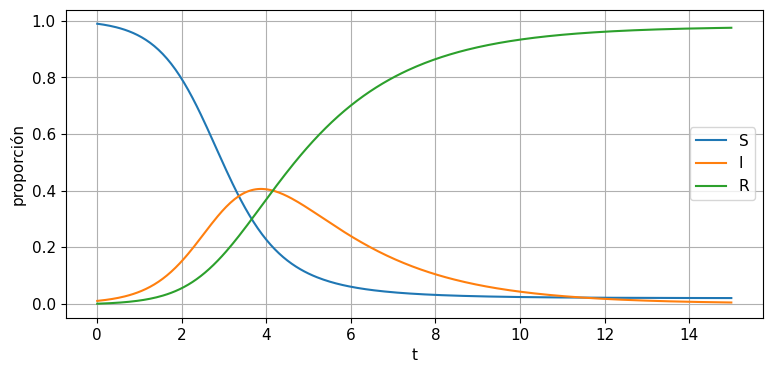

In [7]:
beta,gamma=2.,0.5
def sir(t,y):
    s,i,r=y
    return np.array([-beta*s*i,beta*s*i-gamma*i,gamma*i])
t,y=heun(sir,(0,15),[0.99,0.01,0.],300)
for j,label in enumerate(["S","I","R"]): plt.plot(t,y[:,j],label=label)
plt.xlabel("t"); plt.ylabel("proporción"); plt.legend(); plt.show()
print("Error de conservación:",np.max(abs(y.sum(axis=1)-1)))
print("Valor mínimo:",y.min())

**Interpretación.** La suma debe permanecer cerca de uno y, con este paso, los estados deberían ser no negativos. El máximo de infectados es un observable distinto del valor final; al ajustar parámetros conviene verificar también la precisión de su tiempo y amplitud.

## 8. Tabla de Butcher y diferencia con el trapecio implícito

Heun puede representarse por $c=(0,1)$, $A_{21}=1$ y pesos $b=(1/2,1/2)$. En palabras: el primer estadio usa el inicio, el segundo un paso completo con la primera pendiente y el resultado pondera ambos por igual.

El trapecio implícito es $y_{n+1}=y_n+h[f(t_n,y_n)+f(t_{n+1},y_{n+1})]/2$. Este usa el resultado desconocido en la segunda pendiente y requiere resolver una ecuación. Tiene el mismo orden dos pero diferente región de estabilidad. No se debe confundir iterar el corrector hasta converger con ejecutar exactamente una corrección de Heun.

## 9. Uso práctico y diagnóstico

Heun es una mejora sencilla sobre Euler cuando se necesita orden dos y una implementación explícita. Para decaimiento muy rápido, la condición $kh<2$ puede obligar a usar tantos pasos que un método implícito resulte más conveniente.

Comprueba invariantes lineales, positividad y eventos. En el SIR, un resultado con $S+I+R=1$ y $I<0$ no es aceptable físicamente. En un oscilador, curvas casi periódicas pueden esconder una deriva energética. Define las propiedades requeridas antes de seleccionar el paso.

## 10. Convergencia, error y coste: cómo hacer una comparación justa

Si un método tiene orden global $p=2$, en el régimen asintótico se espera $E(h)\approx C h^p$ para problemas suficientemente suaves y un intervalo temporal fijo. El estimador
$$p_{\rm obs}=\log_2\frac{E(h)}{E(h/2)}$$
solo es significativo mientras el error de referencia y el redondeo sean menores que el error medido. Una trayectoria visualmente correcta puede tener error de fase, sesgo en un observable o errores localizados en transitorios.

Para comparar métodos, cuenta evaluaciones de $f$, resoluciones lineales y, en métodos implícitos, iteraciones de Newton. Un método de más orden puede ser más barato para una precisión dada, pero no necesariamente para una tolerancia muy laxa o una función no suave. Si aparecen discontinuidades o eventos, separa los intervalos suaves y localiza el cambio.

Guarda el tiempo final real de cada integración. Usar `int(T/h)` puede terminar antes de $T$ si el cociente no es entero. En estos ejemplos fijamos el número de pasos y calculamos $h=(T-t_0)/N$ para llegar exactamente al extremo. Una malla de salida fija tampoco debe confundirse con los pasos internos de un solver adaptativo.

## 11. De la simulación a SciML

En un problema inverso se ajusta un parámetro $\theta$ minimizando
$$L_h(\theta)=\sum_i\left[y_h(t_i;\theta)-y_i^{\rm obs}\right]^2.$$
El subíndice $h$ recuerda que estamos optimizando la salida de un simulador discretizado. Si el método de Heun genera un sesgo sistemático, el ajuste puede compensarlo con un parámetro equivocado. Repite la inferencia con una malla más fina y observa si el parámetro estimado cambia.

En una Neural ODE, $f_\theta(t,y)$ puede ser una red, pero el solver conserva sus requisitos de regularidad y estabilidad. Reducir la pérdida de entrenamiento no prueba precisión de integración. Para física diferenciable, una derivada del programa discreto es una sensibilidad de ese programa; hace falta verificar que se estabiliza al refinar la discretización.

Define qué observable importa: valor final, energía, evento, amplitud o una norma de trayectoria. No compares únicamente la apariencia de curvas. Una evaluación científica útil separa error de datos, error de modelo y error numérico, porque mejorar uno de ellos no garantiza mejorar los demás.

| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../7_METODOS_NUMERICOS_PARA_ODE/7_1_Euler.ipynb) | [⏩](../7_METODOS_NUMERICOS_PARA_ODE/7_3_Midpoint.ipynb) |